In [1]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_excel(r"D:\Customer_churn_project\Telco_customer_churn.xlsx")

numeric_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges"
]

categorical_columns = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method"
]

# Convert charges to numbers; zero-tenure customers with blank charges get 0
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"], errors="coerce"
).fillna(0.0)

# Clustering inputs: no Churn Value, Churn Reason, or other outcome fields
X_cluster = df[numeric_columns + categorical_columns].copy()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

cluster_preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_columns),
    ("cat", categorical_transformer, categorical_columns)
])

X_cluster_encoded = cluster_preprocessor.fit_transform(X_cluster)

print("Customers:", X_cluster_encoded.shape[0])
print("Encoded features:", X_cluster_encoded.shape[1])

Customers: 7043
Encoded features: 46


In [2]:
scores = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_cluster_encoded)

    silhouette = silhouette_score(
        X_cluster_encoded,
        labels,
        sample_size=2000,
        random_state=42
    )

    scores.append({
        "clusters": k,
        "silhouette": silhouette,
        "inertia": model.inertia_
    })

pd.DataFrame(scores).round(3)

,clusters,silhouette,inertia
0,2,0.252,63220.514
1,3,0.250,50192.539
2,4,0.203,46439.680
3,5,0.185,44113.450
4,6,0.148,42344.048
5,7,0.131,40876.586
6,8,0.128,39636.122


In [3]:
cluster_model = KMeans(n_clusters=3, n_init=10, random_state=42)
df["Cluster"] = cluster_model.fit_predict(X_cluster_encoded)

cluster_summary = df.groupby("Cluster").agg(
    Customers=("CustomerID", "size"),
    Churn_Rate=("Churn Value", "mean"),
    Median_Tenure=("Tenure Months", "median"),
    Avg_Monthly_Charges=("Monthly Charges", "mean"),
    Avg_Total_Charges=("Total Charges", "mean")
)

cluster_summary["Churn_Rate"] *= 100
display(cluster_summary.round(1))

print("Contract mix within each cluster (%):")
display(
    pd.crosstab(df["Cluster"], df["Contract"], normalize="index")
      .mul(100).round(1)
)

print("Internet service mix within each cluster (%):")
display(
    pd.crosstab(df["Cluster"], df["Internet Service"], normalize="index")
      .mul(100).round(1)
)

,Customers,Churn_Rate,Median_Tenure,Avg_Monthly_Charges,Avg_Total_Charges
Cluster,,,,,
0,3192,44.0,12.0,67.9,1019.2
1,1526,7.4,25.0,21.1,662.6
2,2325,15.1,60.0,89.2,5071.7


Contract mix within each cluster (%):


Contract,Month-to-month,One year,Two year
Cluster,,,
0,86.9,10.6,2.4
1,34.3,23.9,41.8
2,24.8,33.1,42.1


Internet service mix within each cluster (%):


Internet Service,DSL,Fiber optic,No
Cluster,,,
0,47.7,52.3,0.0
1,0.0,0.0,100.0
2,38.7,61.3,0.0


In [4]:
cluster_0_churners = df[
    (df["Cluster"] == 0) &
    (df["Churn Value"] == 1)
]

display(cluster_0_churners["Churn Reason"].value_counts())

Churn Reason
Attitude of support person                   142
Competitor offered higher download speeds    140
Don't know                                   126
Competitor offered more data                 115
Competitor made better offer                 104
Competitor had better devices                102
Attitude of service provider                 100
Network reliability                           81
Lack of self-service on Website               76
Price too high                                72
Product dissatisfaction                       71
Service dissatisfaction                       65
Extra data charges                            42
Moved                                         37
Limited range of services                     34
Long distance charges                         34
Lack of affordable download/upload speed      28
Poor expertise of online support              16
Poor expertise of phone support               14
Deceased                                       6
Name: c

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from sklearn.cluster import AgglomerativeClustering

# Use every customer's encoded features
X_all = (
    X_cluster_encoded.toarray()
    if hasattr(X_cluster_encoded, "toarray")
    else np.asarray(X_cluster_encoded)
)

# Build the full hierarchy and assign all customers to 3 clusters
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward",
    compute_full_tree=True,
    compute_distances=True
)

df["Agg_Cluster"] = hierarchical_model.fit_predict(X_all)

print("Customers clustered:", len(df))
print(df["Agg_Cluster"].value_counts().sort_index())

Customers clustered: 7043
Agg_Cluster
0    3854
1    1526
2    1663
Name: count, dtype: int64


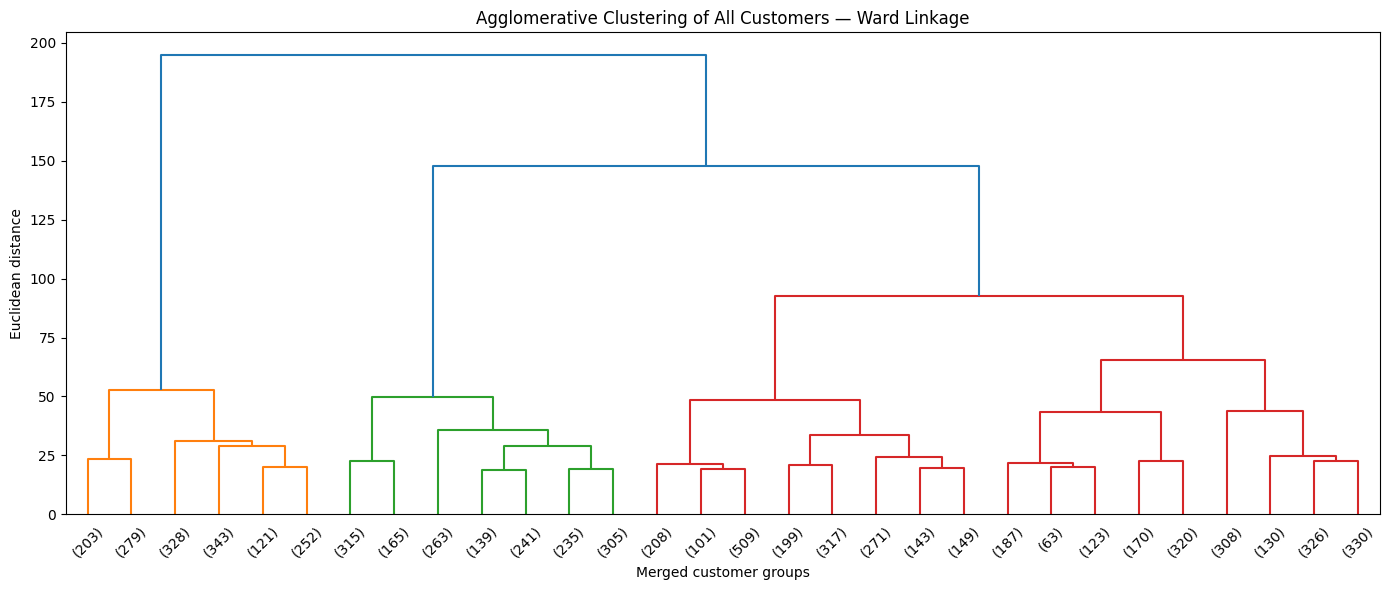

In [6]:
children = hierarchical_model.children_
distances = hierarchical_model.distances_
n_customers = X_all.shape[0]

# Count how many original customers are represented by each merge
counts = np.zeros(children.shape[0])

for i, (left, right) in enumerate(children):
    left_count = 1 if left < n_customers else counts[left - n_customers]
    right_count = 1 if right < n_customers else counts[right - n_customers]
    counts[i] = left_count + right_count

linkage_matrix = np.column_stack([children, distances, counts]).astype(float)

plt.figure(figsize=(14, 6))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)
plt.title("Agglomerative Clustering of All Customers — Ward Linkage")
plt.xlabel("Merged customer groups")
plt.ylabel("Euclidean distance")
plt.tight_layout()
plt.show()

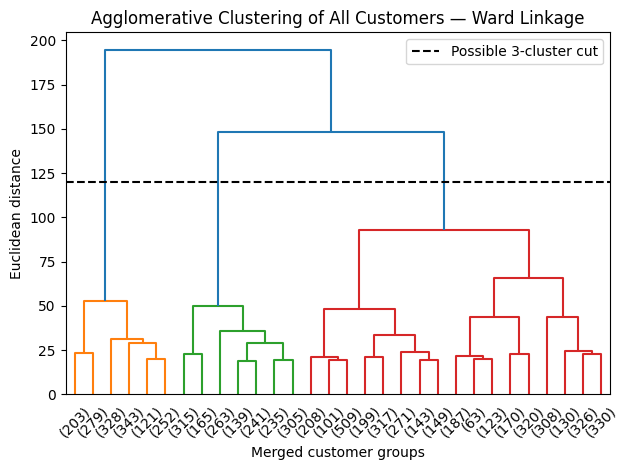

In [7]:
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.axhline(
    y=120,
    color="black",
    linestyle="--",
    label="Possible 3-cluster cut"
)

plt.title("Agglomerative Clustering of All Customers — Ward Linkage")
plt.xlabel("Merged customer groups")
plt.ylabel("Euclidean distance")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

# Use the same feature matrix that was used to fit both methods
X_eval = (
    X_cluster_encoded.toarray()
    if hasattr(X_cluster_encoded, "toarray")
    else np.asarray(X_cluster_encoded)
)

kmeans_labels = df["Cluster"].to_numpy()
agg_labels = df["Agg_Cluster"].to_numpy()

# Internal clustering scores: calculate on all customers
scores = []

for name, labels in [
    ("K-Means", kmeans_labels),
    ("Agglomerative Ward", agg_labels)
]:
    scores.append({
        "Method": name,
        "Clusters": len(np.unique(labels)),
        "Silhouette": silhouette_score(X_eval, labels),
        "Davies-Bouldin": davies_bouldin_score(X_eval, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_eval, labels)
    })

display(pd.DataFrame(scores).set_index("Method").round(3))

# Compare whether the two methods assign customers to similar groups
print(
    "Adjusted Rand Index:",
    round(adjusted_rand_score(kmeans_labels, agg_labels), 3)
)

# Profile clusters and compare their churn rates
for method, column in [
    ("K-Means", "Cluster"),
    ("Agglomerative Ward", "Agg_Cluster")
]:
    print(f"\n{method} cluster profiles:")
    profile = df.groupby(column).agg(
        Customers=("Churn Value", "size"),
        Churn_Rate=("Churn Value", "mean"),
        Median_Tenure=("Tenure Months", "median"),
        Avg_Monthly_Charges=("Monthly Charges", "mean")
    )
    profile["Churn_Rate"] *= 100
    display(profile.round(1))

,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
Method,,,,
K-Means,3,0.251,1.603,2243.347
Agglomerative Ward,3,0.231,1.650,2012.936


Adjusted Rand Index: 0.693

K-Means cluster profiles:


,Customers,Churn_Rate,Median_Tenure,Avg_Monthly_Charges
Cluster,,,,
0,3192,44.0,12.0,67.9
1,1526,7.4,25.0,21.1
2,2325,15.1,60.0,89.2



Agglomerative Ward cluster profiles:


,Customers,Churn_Rate,Median_Tenure,Avg_Monthly_Charges
Agg_Cluster,,,,
0,3854,39.8,16.0,69.4
1,1526,7.4,25.0,21.1
2,1663,13.4,63.0,94.2


In [9]:
pd.crosstab(
    df["Cluster"],
    df["Agg_Cluster"],
    margins=True
)

Agg_Cluster,0,1,2,All
Cluster,,,,
0,3145,0,47,3192
1,0,1526,0,1526
2,709,0,1616,2325
All,3854,1526,1663,7043


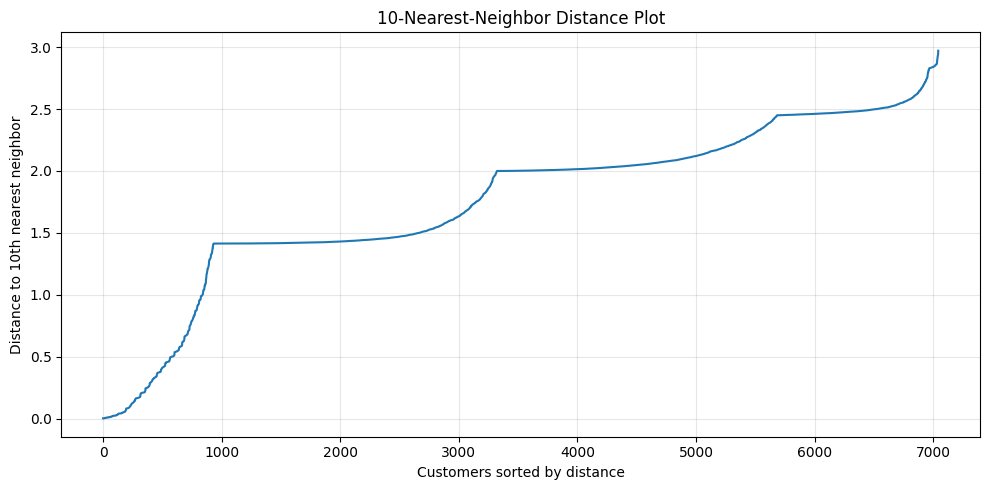

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

X_dbscan = X_cluster_encoded
min_samples = 10

neighbors = NearestNeighbors(
    n_neighbors=min_samples,
    n_jobs=-1
)
neighbors.fit(X_dbscan)

distances, _ = neighbors.kneighbors(X_dbscan)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.title(f"{min_samples}-Nearest-Neighbor Distance Plot")
plt.xlabel("Customers sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
import pandas as pd
from sklearn.cluster import DBSCAN

X_dbscan = X_cluster_encoded
min_samples = 10
eps_values = [1.8, 2.0, 2.1]

results = []

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        n_jobs=-1
    )
    labels = model.fit_predict(X_dbscan)

    cluster_sizes = pd.Series(labels[labels != -1]).value_counts()

    results.append({
        "eps": eps,
        "clusters_found": len(cluster_sizes),
        "noise_customers": int((labels == -1).sum()),
        "noise_percent": round((labels == -1).mean() * 100, 1),
        "largest_cluster": int(cluster_sizes.max()) if len(cluster_sizes) else 0,
        "smallest_cluster": int(cluster_sizes.min()) if len(cluster_sizes) else 0
    })

display(pd.DataFrame(results))

,eps,clusters_found,noise_customers,noise_percent,largest_cluster,smallest_cluster
0,1.8,3,2738,38.9,2603,181
1,2.0,3,2598,36.9,2720,203
2,2.1,5,889,12.6,4528,5


In [12]:
from sklearn.cluster import DBSCAN
import pandas as pd

dbscan_model = DBSCAN(
    eps=2.0,
    min_samples=10,
    n_jobs=-1
)

df["DBSCAN_Cluster"] = dbscan_model.fit_predict(X_cluster_encoded)

print("Customers per DBSCAN label:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

# -1 means DBSCAN marked the customer as noise
dbscan_profile = df.groupby("DBSCAN_Cluster").agg(
    Customers=("Churn Value", "size"),
    Churn_Rate=("Churn Value", "mean"),
    Median_Tenure=("Tenure Months", "median"),
    Avg_Monthly_Charges=("Monthly Charges", "mean")
)

dbscan_profile["Churn_Rate"] *= 100
display(dbscan_profile.round(1))

Customers per DBSCAN label:
DBSCAN_Cluster
-1    2598
 0    2720
 1    1522
 2     203
Name: count, dtype: int64


,Customers,Churn_Rate,Median_Tenure,Avg_Monthly_Charges
DBSCAN_Cluster,,,,
-1,2598,16.2,44.0,74.7
0,2720,45.6,16.0,82.0
1,1522,7.4,25.0,21.1
2,203,46.8,6.0,33.5


In [13]:
for cluster_id in [0, 2]:
    churners = df[
        (df["DBSCAN_Cluster"] == cluster_id) &
        (df["Churn Value"] == 1)
    ]

    print(f"\nDBSCAN cluster {cluster_id} — churn reasons:")
    display(churners["Churn Reason"].value_counts())


DBSCAN cluster 0 — churn reasons:


Churn Reason
Competitor offered higher download speeds    130
Attitude of support person                   128
Competitor offered more data                 103
Don't know                                   100
Competitor made better offer                  97
Competitor had better devices                 89
Attitude of service provider                  87
Network reliability                           71
Product dissatisfaction                       70
Price too high                                64
Lack of self-service on Website               64
Service dissatisfaction                       59
Extra data charges                            44
Moved                                         31
Long distance charges                         29
Limited range of services                     24
Lack of affordable download/upload speed      23
Poor expertise of online support              12
Poor expertise of phone support               10
Deceased                                       4
Name: c


DBSCAN cluster 2 — churn reasons:


Churn Reason
Attitude of service provider                 11
Competitor offered more data                 10
Attitude of support person                    9
Competitor had better devices                 8
Competitor offered higher download speeds     8
Don't know                                    8
Product dissatisfaction                       7
Service dissatisfaction                       5
Limited range of services                     5
Price too high                                4
Competitor made better offer                  4
Lack of self-service on Website               4
Network reliability                           3
Lack of affordable download/upload speed      3
Long distance charges                         2
Deceased                                      1
Extra data charges                            1
Poor expertise of online support              1
Moved                                         1
Name: count, dtype: int64